# Inspecao rapida dos embeddings salvos

Este notebook ajuda a listar, carregar e analisar os embeddings exportados em `results/embeddings`.

In [1]:
import os
import glob
import numpy as np
import torch
import pandas as pd
import matplotlib.pyplot as plt

ROOT = os.path.abspath(os.path.join(os.getcwd(), '..')) if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
EMB_ROOT = os.path.join(ROOT, 'results', 'embeddings')
print('Project root:', ROOT)
print('Embeddings root:', EMB_ROOT)

Project root: c:\Users\Otavio HB Francisco\Documents\Documents\MESTRADO\isoladas\multimodal\projeto\DPED-Sistemas-Hibridos
Embeddings root: c:\Users\Otavio HB Francisco\Documents\Documents\MESTRADO\isoladas\multimodal\projeto\DPED-Sistemas-Hibridos\results\embeddings


In [2]:
run_dirs = sorted([d for d in glob.glob(os.path.join(EMB_ROOT, '*')) if os.path.isdir(d)])
print(f'Total de execucoes com embeddings: {len(run_dirs)}')
for i, d in enumerate(run_dirs, start=1):
    print(f'{i:02d} - {os.path.basename(d)}')

if not run_dirs:
    raise RuntimeError('Nenhuma pasta encontrada em results/embeddings. Rode um experimento primeiro.')

Total de execucoes com embeddings: 1
01 - glue_sst2_non-private_eps8p0


In [3]:
# Escolha a pasta desejada.
# Por padrao, usamos a ultima em ordem alfabetica.
selected_run = run_dirs[-1]
print('Run selecionada:', os.path.basename(selected_run))

pt_path = os.path.join(selected_run, 'token_embeddings.pt')
npy_path = os.path.join(selected_run, 'token_embeddings.npy')
meta_path = os.path.join(selected_run, 'metadata.txt')

if os.path.exists(pt_path):
    emb = torch.load(pt_path, map_location='cpu')
    emb = emb.numpy() if isinstance(emb, torch.Tensor) else np.array(emb)
elif os.path.exists(npy_path):
    emb = np.load(npy_path)
else:
    raise FileNotFoundError('Nao encontrei token_embeddings.pt nem token_embeddings.npy na pasta selecionada.')

print('Shape:', emb.shape)
print('Dtype:', emb.dtype)

if os.path.exists(meta_path):
    print('\nMetadata:')
    with open(meta_path, 'r', encoding='utf-8') as f:
        print(f.read())

Run selecionada: glue_sst2_non-private_eps8p0
Shape: (30522, 768)
Dtype: float32

Metadata:
saved_at=2026-11-05T14:11:33
dataset=glue
task=sst2
method=non-private
epsilon=8.0
shape=(30522, 768)
files=token_embeddings.pt,token_embeddings.npy



In [4]:
flat = emb.reshape(-1)
row_norms = np.linalg.norm(emb, axis=1)

summary = pd.Series({
    'vocab_size': emb.shape[0],
    'embedding_dim': emb.shape[1],
    'global_min': float(flat.min()),
    'global_max': float(flat.max()),
    'global_mean': float(flat.mean()),
    'global_std': float(flat.std()),
    'norm_mean': float(row_norms.mean()),
    'norm_std': float(row_norms.std()),
    'norm_min': float(row_norms.min()),
    'norm_max': float(row_norms.max()),
})
display(summary.to_frame('value'))

,value
vocab_size,30522.000000
embedding_dim,768.000000
global_min,-0.950369
global_max,0.872892
global_mean,-0.028025
global_std,0.042667
norm_mean,1.401414
norm_std,0.193216
norm_min,0.765710
norm_max,2.044597


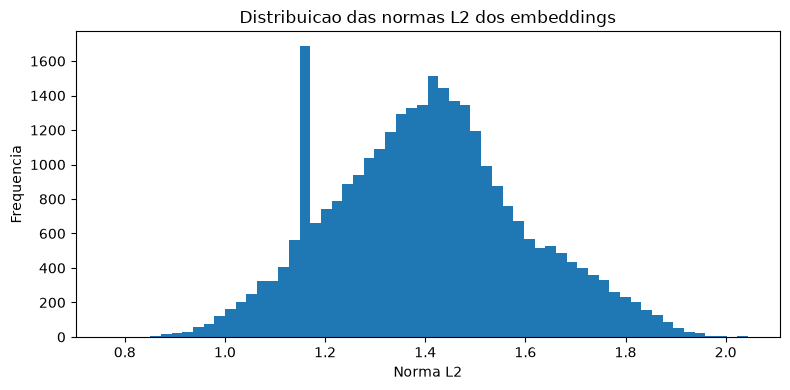

In [5]:
plt.figure(figsize=(8, 4))
plt.hist(row_norms, bins=60)
plt.title('Distribuicao das normas L2 dos embeddings')
plt.xlabel('Norma L2')
plt.ylabel('Frequencia')
plt.tight_layout()
plt.show()

In [6]:
# Similaridade coseno entre alguns tokens (indices) para uma checagem rapida
sample_ids = [101, 102, 1037, 2003, 2023]  # [CLS], [SEP], 'a', 'is', 'this' em BERT uncased
sample_ids = [i for i in sample_ids if i < emb.shape[0]]
sample = emb[sample_ids]
sample = sample / (np.linalg.norm(sample, axis=1, keepdims=True) + 1e-12)
cos_sim = sample @ sample.T

cos_df = pd.DataFrame(cos_sim, index=sample_ids, columns=sample_ids)
display(cos_df.round(4))

,101,102,1037,2003,2023
101,1.0000,0.4137,0.0270,0.0455,0.0235
102,0.4137,1.0000,0.0938,0.1185,0.0673
1037,0.0270,0.0938,1.0000,0.3993,0.5301
2003,0.0455,0.1185,0.3993,1.0000,0.3771
2023,0.0235,0.0673,0.5301,0.3771,1.0000
